# Boiling an Egg: Simple FEM Model

This notebook presents a finite-element simulation of heat transfer during egg boiling.
We solve the transient heat equation in axisymmetric cylindrical coordinates:

$$\rho\, C_p \frac{\partial T}{\partial t} = \nabla \cdot (\kappa \nabla T)$$

where $\rho$ is density, $C_p$ is specific heat capacity, $\kappa$ is thermal
conductivity, and $T$ is temperature.

In axisymmetric form (with radial coordinate $r$ and axial coordinate $z$), the
divergence operator becomes:

$$\rho\, C_p \frac{\partial T}{\partial t} = \frac{1}{r}\frac{\partial}{\partial r}\left(r\,\kappa\frac{\partial T}{\partial r}\right) + \frac{\partial}{\partial z}\left(\kappa\frac{\partial T}{\partial z}\right)$$

**Simplifications in this first notebook:**

- The egg is modelled as a simple circle (cross-section of a sphere) rather than a realistic egg shape.
- Material properties (density, conductivity, specific heat) are treated as constants (egg white properties).
- The boundary condition is a fixed boiling-water temperature on the shell.

Later notebooks will introduce realistic egg geometry and temperature-dependent material properties.

## Setup

Import the `egg_fem` package modules along with standard scientific Python libraries.

In [1]:
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt

from egg_fem.materials import (
    EggMaterial,
    WHITE_CONST,
    YOLK_CONST,
    T_BOILING,
    T_ROOM,
    T_FRIDGE,
    WHITE_DENATURATION_K,
    YOLK_DENATURATION_K,
)
from egg_fem.geometry import create_circular_mesh
from egg_fem.solver import HeatSolver

## Mesh Generation

We create a circular mesh representing the axisymmetric cross-section of a
spherical egg. The radius is set to 22 mm (a typical medium egg) and the mesh
element size is 1.5 mm, providing a good balance between accuracy and
computation time.

The mesh includes two named boundaries:
- **"shell"** -- the outer boundary where boiling water contacts the egg
- **"axis"** -- the axis of symmetry (zero-flux boundary condition)

In [2]:
radius = 0.022       # 22 mm
mesh_size = 0.0015   # 1.5 mm element size

mesh = create_circular_mesh(radius=radius, mesh_size=mesh_size)

print(f"Number of nodes:    {mesh.p.shape[1]}")
print(f"Number of elements: {mesh.t.shape[1]}")


Number of nodes:    469
Number of elements: 858


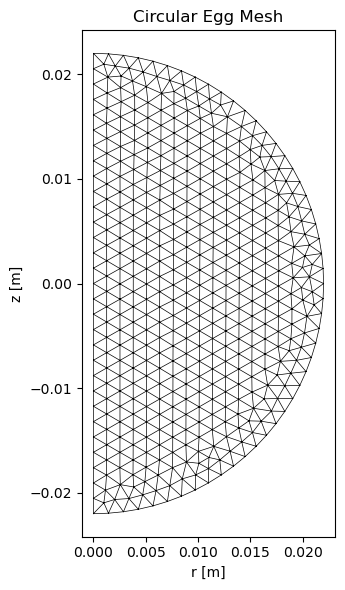

In [3]:
fig, ax = plt.subplots(figsize=(6, 6))
mesh.draw(ax=ax)
ax.set_xlabel('r [m]')
ax.set_ylabel('z [m]')
ax.set_title('Circular Egg Mesh')
ax.set_aspect('equal')
plt.tight_layout()
plt.show()

## Material Properties

For this simple model we use constant material properties taken from egg white.
The `WHITE_CONST` object is an `EggMaterial` dataclass that stores density,
thermal conductivity, and specific heat capacity.

In [4]:
material = WHITE_CONST

print(f"Material: constant egg-white properties")
print(f"  Density (rho):          {material.density(T_ROOM):.1f} kg/m^3")
print(f"  Conductivity (kappa):   {material.conductivity(T_ROOM):.4f} W/(m*K)")
print(f"  Specific heat (Cp):     {material.specific_heat(T_ROOM):.1f} J/(kg*K)")
print()
print(f"Reference temperatures:")
print(f"  T_ROOM    = {T_ROOM:.2f} K  ({T_ROOM - 273.15:.1f} deg C)")
print(f"  T_BOILING = {T_BOILING:.2f} K  ({T_BOILING - 273.15:.1f} deg C)")
print(f"  T_FRIDGE  = {T_FRIDGE:.2f} K  ({T_FRIDGE - 273.15:.1f} deg C)")

Material: constant egg-white properties
  Density (rho):          1038.0 kg/m^3
  Conductivity (kappa):   0.5500 W/(m*K)
  Specific heat (Cp):     3800.0 J/(kg*K)

Reference temperatures:
  T_ROOM    = 293.15 K  (20.0 deg C)
  T_BOILING = 373.15 K  (100.0 deg C)
  T_FRIDGE  = 281.15 K  (8.0 deg C)


## Run Simulation

We set up the `HeatSolver` with:
- **Initial temperature:** room temperature (approximately 20 deg C)
- **Boundary temperature:** boiling water (100 deg C)
- **Time step:** 1 second
- **Total time:** 720 seconds (12 minutes)

The solver uses implicit time stepping (backward Euler) to march the solution
forward in time.

In [5]:
dt = 1.0           # time step [s]
t_end = 720.0      # total simulation time [s] (12 minutes)

solver = HeatSolver(
    mesh=mesh,
    material=material,
    T_init=T_ROOM,
    T_boundary=T_BOILING,
    dt=dt,
)

solver.run(t_end)

print(f"Simulation complete.")
print(f"  Time steps: {len(solver.times)}")
print(f"  Time range: 0 -- {solver.times[-1]:.0f} s")

  t =   60.0 s (1.0 min)  T_center = 20.0 °C
  t =  120.0 s (2.0 min)  T_center = 20.3 °C
  t =  180.0 s (3.0 min)  T_center = 23.1 °C
  t =  240.0 s (4.0 min)  T_center = 29.2 °C
  t =  300.0 s (5.0 min)  T_center = 37.0 °C
  t =  360.0 s (6.0 min)  T_center = 45.2 °C
  t =  420.0 s (7.0 min)  T_center = 52.9 °C
  t =  480.0 s (8.0 min)  T_center = 59.9 °C
  t =  540.0 s (9.0 min)  T_center = 65.9 °C
  t =  600.0 s (10.0 min)  T_center = 71.2 °C
  t =  660.0 s (11.0 min)  T_center = 75.6 °C
  t =  720.0 s (12.0 min)  T_center = 79.4 °C
Simulation complete.
  Time steps: 721
  Time range: 0 -- 720 s


## Temperature at Center vs Time

We extract the temperature history at the center of the egg (the point that
heats up last) and plot it against time. Two horizontal reference lines mark
the approximate protein denaturation temperatures:

- **Egg white denaturation:** ~63 deg C -- the white starts to solidify
- **Egg yolk denaturation:** ~65 deg C -- the yolk starts to set

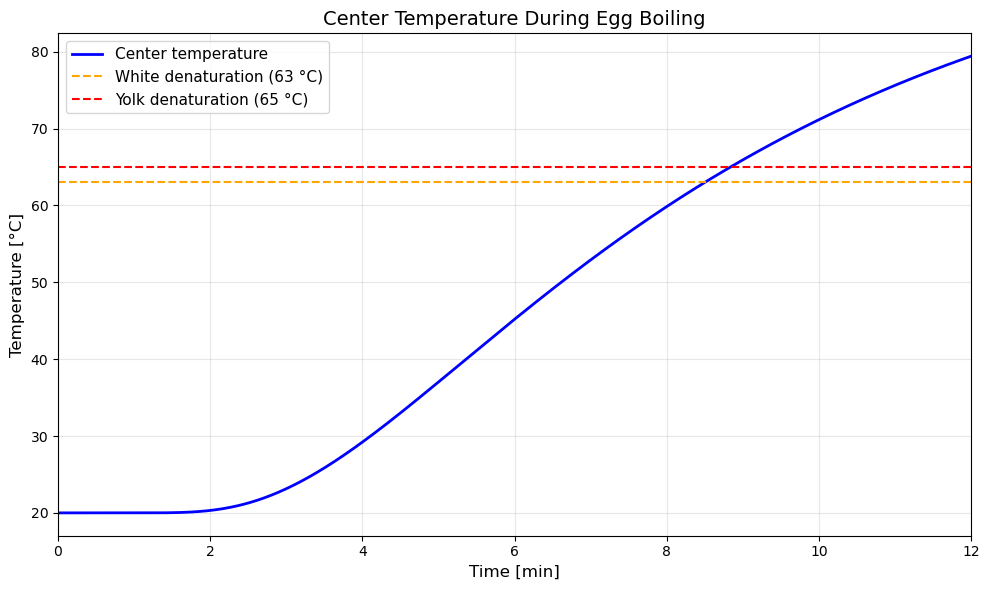

In [6]:
times_arr, T_center_C = solver.center_temperature_history()

# Convert to minutes for plotting
times_min = times_arr / 60.0

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(times_min, T_center_C, 'b-', linewidth=2, label='Center temperature')

# Denaturation reference lines
T_white_denat_C = WHITE_DENATURATION_K - 273.15
T_yolk_denat_C = YOLK_DENATURATION_K - 273.15
ax.axhline(T_white_denat_C, color='orange', linestyle='--', linewidth=1.5,
           label=f'White denaturation ({T_white_denat_C:.0f} °C)')
ax.axhline(T_yolk_denat_C, color='red', linestyle='--', linewidth=1.5,
           label=f'Yolk denaturation ({T_yolk_denat_C:.0f} °C)')

ax.set_xlabel('Time [min]', fontsize=12)
ax.set_ylabel('Temperature [°C]', fontsize=12)
ax.set_title('Center Temperature During Egg Boiling', fontsize=14)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
ax.set_xlim(0, t_end / 60)
plt.tight_layout()
plt.show()

## Temperature Field Snapshots

To visualise how the heat front propagates inward from the shell, we plot the
full 2-D temperature field at six time instants spanning the 12-minute cook.
Each subplot uses Gouraud shading for a smooth colour map, with temperatures
displayed in degrees Celsius.

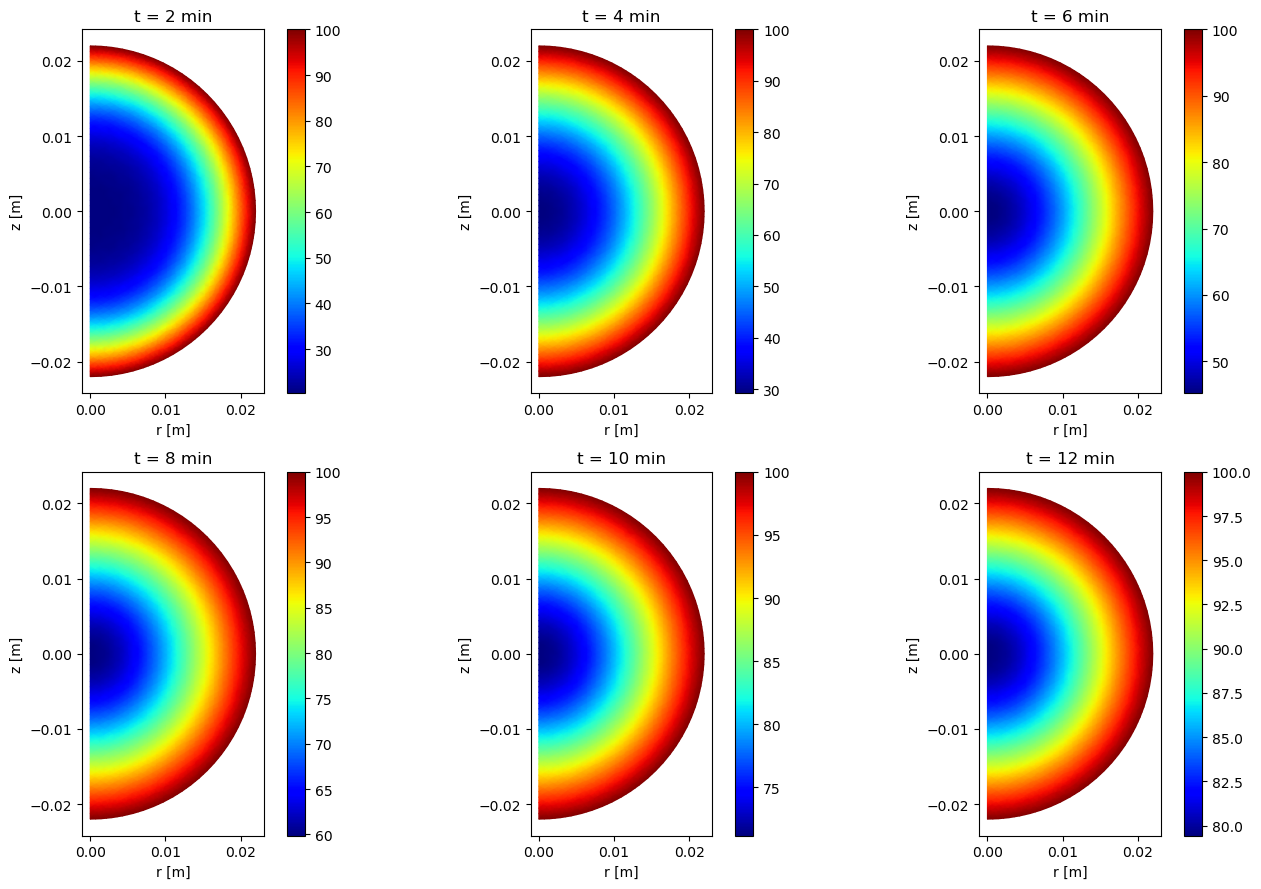

In [7]:
from skfem import Basis, ElementTriP1
from skfem.visuals.matplotlib import plot as fem_plot

basis = Basis(mesh, ElementTriP1())

fig, axes = plt.subplots(2, 3, figsize=(14, 9))
snap_times_min = [2, 4, 6, 8, 10, 12]

for ax, t_min in zip(axes.flat, snap_times_min):
    step_idx = int(t_min * 60 / dt)
    T_celsius = solver.temperatures[step_idx] - 273.15
    fem_plot(basis, T_celsius, ax=ax, shading='gouraud', colorbar=True)
    ax.set_title(f't = {t_min} min')
    ax.set_xlabel('r [m]')
    ax.set_ylabel('z [m]')
    ax.set_aspect('equal')

plt.tight_layout()
plt.show()

## Summary

This simple model provides a qualitative understanding of how heat penetrates
an egg during boiling:

- The outer layers heat up quickly while the center remains cool for several
  minutes.
- The center temperature rises in a characteristic S-curve, eventually
  approaching the boiling-water temperature.
- Protein denaturation (solidification) proceeds as an inward-moving front.

**Limitations of this model:**

- A circular cross-section does not capture the true egg shape (which is
  slightly elongated with one blunt end).
- Constant material properties ignore the fact that thermal conductivity and
  specific heat change with temperature and differ between white and yolk.

The **next notebook** (`02_realistic_geometry.ipynb`) addresses these
limitations by introducing a realistic egg contour and spatially varying,
temperature-dependent material properties.